# Multi-Site Capacity Allocation

**A personal modelling project by Tom Demir**

---

### What this is, and what it is not

This notebook is a **personal modelling project**. It is inspired by my role as Business
Manager at AMJE (Arts et Métiers Junior-Entreprise), where I lead the Commercial Offers
workstream of the BU Manufacturing venture. It is **not** an official AMJE mandate, **not**
a deliverable requested by AMJE management, and **not** a tool deployed in the organisation.

**All numerical data in this notebook is synthetic and illustrative. None of it is AMJE's actual
figures.** No real order volume, margin, machine capacity, or revenue figure from AMJE appears
anywhere in this notebook. What is real and public is only the geography: the eight Arts et
Métiers campus cities, and the distances between French cities.

### Why I built it

My existing technical portfolio is built on machine learning, Monte Carlo simulation and
heuristic decision systems. None of it involves classical mathematical programming: linear
programming, integer programming, duality. This project exists to close that gap by
formulating a genuine mixed-integer linear program, solving it, and then working out how
far its answers can actually be trusted.

The emphasis throughout is on **why** each modelling choice is made, not just on producing a
number. The final sections on the linear relaxation and on duality are the point of the
exercise, not an appendix to it.

## 1. The problem in words

The BU Manufacturing venture pools the manufacturing capacity of eight Arts et Métiers
campuses: CNC turning, CNC milling on polymers, conventional machining, sheet metal work,
FDM additive manufacturing and electrical discharge machining, and sells it as a structured
service offering.

A stream of commercial orders arrives. Each order:

- carries a **gross margin** if it is delivered,
- consumes a certain number of **machine-hours** on one or more process types,
- originates from a **client located somewhere in France**.

The decision I face as Business Manager is twofold and simultaneous:

1. **Which orders do we accept?** Capacity is finite; we cannot take everything.
2. **Which campus does each accepted order go to?** The client never specifies this.

Two real constraints govern the second decision:

- **Machine compatibility, a hard constraint.** A campus can only take an order if it
  physically owns every process the order requires. This includes an exclusion perimeter:
  metal CNC milling and non-FDM additive manufacturing are not available anywhere in the
  network, so any order requiring them cannot be served at all.
- **Geographic proximity, a cost rather than a constraint.** A distant campus is not forbidden.
  It is more expensive. Modelling it as a cost rather than a hard rule is a deliberate
  choice, discussed in Section 3.

### Why this is a mixed-integer program and not a linear program

An order is **indivisible**. We do not machine 40% of a prototype in Lille and 60% in Metz.
The assignment decision is therefore binary, and binary variables are what make this an
integer program. Section 10 shows concretely what happens when we drop that requirement:
the relaxed solution starts splitting orders across campuses, which is mathematically valid
and physically meaningless.

## 2. Mathematical formulation

### Sets

| Symbol | Meaning |
|---|---|
| $I$ | set of commercial orders, indexed by $i$ |
| $C$ | set of campuses, indexed by $c$ |
| $P$ | set of process types, indexed by $p$ |

### Parameters

| Symbol | Meaning | Unit |
|---|---|---|
| $m_i$ | gross margin of order $i$ if delivered | € |
| $h_{i,p}$ | machine-hours of process $p$ required by order $i$ | h |
| $K_{c,p}$ | machine-hours of process $p$ available at campus $c$ over the horizon | h |
| $d_{i,c}$ | distance between the client of order $i$ and campus $c$ | km |
| $\tau$ | logistics cost per kilometre | €/km |

A campus $c$ **lacks** process $p$ exactly when $K_{c,p} = 0$. The exclusion perimeter is
therefore encoded in the data, not hard-coded as a rule: for the two excluded processes,
$K_{c,p} = 0$ for every campus $c$.

### Compatibility set

$$\mathcal{A} = \bigl\{ (i,c) \in I \times C \;:\; h_{i,p} > 0 \Rightarrow K_{c,p} > 0
\quad \forall p \in P \bigr\}$$

Only compatible pairs get a decision variable. Incompatible assignments are not forbidden
by a constraint; they simply do not exist in the model. This keeps the formulation smaller
and makes infeasible assignments structurally impossible rather than merely penalised.

### Decision variables

$$x_{i,c} \in \{0,1\}, \qquad (i,c) \in \mathcal{A}$$

$x_{i,c} = 1$ if order $i$ is accepted **and** assigned to campus $c$; $0$ otherwise.

Note that acceptance is not a separate variable. Order $i$ is accepted if and only if
$\sum_c x_{i,c} = 1$, so an explicit acceptance variable $y_i$ would carry no information the
$x_{i,c}$ do not already carry. It would not change the problem either. Adding $y_i$, linked
either by $y_i = \sum_c x_{i,c}$ or by $\sum_c x_{i,c} \le y_i$, leaves the relaxation bound
exactly where it was; Section 10.2 runs both variants and prints the three bounds side by side.
The formulation is kept lean because there is nothing to gain by expanding it, not because the
alternative is weaker.

### Objective

$$\max \sum_{(i,c) \in \mathcal{A}} \bigl( \underbrace{m_i}_{\text{gross margin}} -
\underbrace{\tau \, d_{i,c}}_{\text{logistics cost}} \bigr) \, x_{i,c}$$

Both terms are in euros. **This matters for the dual reading in Section 10**: if distance
were penalised in kilometres or in an arbitrary score, the objective would mix units and the
shadow price "euros per machine-hour" would lose its dimensional meaning.

### Constraints

**(C1) Each order is assigned at most once**

$$\sum_{c \,:\, (i,c) \in \mathcal{A}} x_{i,c} \;\le\; 1 \qquad \forall i \in I$$

The inequality is $\le 1$, not $= 1$. Writing $= 1$ would force every order to be accepted,
which makes the model infeasible as soon as capacity is short. Worse, it would remove the
model's ability to express a refusal. Refusing an order is a *decision*, not a failure.

**(C2) Campus capacity per process**

$$\sum_{i \,:\, (i,c) \in \mathcal{A}} h_{i,p} \, x_{i,c} \;\le\; K_{c,p}
\qquad \forall c \in C, \; \forall p \in P$$

One constraint per (campus, process) pair. These are the constraints whose dual values we
will read in Section 10: the marginal euro value of one additional machine-hour.

### Structure

This is a **generalised assignment problem**: items (orders) assigned to bins (campuses)
with multi-dimensional capacity (one dimension per process) and assignment-dependent profit.

The class is NP-hard. That is a statement about worst cases as the problem grows, and it
settles nothing about an instance of 28 orders and 8 campuses, which branch and bound disposes
of in well under a second. Complexity theory is therefore the wrong argument for building this
model, and Section 7.2 makes the right one instead: it runs the greedy rule the model is meant
to replace and measures what the model buys over it.

## 3. Setup and modelling decision on geography

One modelling choice deserves to be recorded explicitly, because it drives everything in
Section 10.

**Geographic proximity is modelled as a cost term in the objective, not as a hard constraint.**

Had I written a hard rule, say *"no assignment beyond 300 km"*, two things would break:

1. **Refusals become unreadable.** When an order is rejected I could no longer tell whether
   it was rejected because no campus had free capacity, or because the only campus that did
   was 320 km away. A hard constraint removes options silently and never displays the price
   of that removal.

2. **The dual values on capacity become contaminated.** A shadow price on capacity is only
   interpretable if the objective captures every real economic trade-off. Push geography out
   of the objective and into a hard rule, and the capacity dual becomes a hybrid number
   blending genuine scarcity with a restriction I invented myself. I could read a high dual
   on campus A and conclude we should invest in machines there, when the real problem was
   that my own 300 km rule excluded campus B, which had idle capacity.

There is also a robustness argument: a hard constraint can render the problem *infeasible*
where reality merely makes it *expensive*. That is a modelling failure, not a result.

In [1]:
# Standard scientific stack + PuLP.
# If PuLP is not installed:  pip install pulp
import pulp
import numpy as np
import pandas as pd
from math import radians, sin, cos, asin, sqrt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

print("PuLP version:", pulp.__version__)
print("Available solvers:", pulp.listSolvers(onlyAvailable=True))

PuLP version: 3.3.2
Available solvers: ['PULP_CBC_CMD']


## 4. Data

### 4.1 Campuses: the real geography

The eight Arts et Métiers campus cities and their coordinates are public information. This
is the only non-synthetic data in the notebook.

In [2]:
# Real ENSAM campus cities (public information). Coordinates in (lat, lon).
CAMPUS_COORD = {
    "Aix":      (43.529,  5.447),   # Aix-en-Provence
    "Angers":   (47.478, -0.563),
    "Bordeaux": (44.806, -0.596),   # Talence
    "Chalons":  (48.957,  4.365),   # Chalons-en-Champagne
    "Cluny":    (46.434,  4.659),
    "Lille":    (50.633,  3.059),
    "Metz":     (49.119,  6.176),
    "Paris":    (48.857,  2.352),
}
C = list(CAMPUS_COORD)

# Process types.
# The first six exist somewhere in the network. The last two form the EXCLUSION PERIMETER:
# no campus owns them, so no order requiring them can ever be served.
P_SERVED   = ["CNC_TURNING", "CNC_MILLING_POLYMER", "CONVENTIONAL_MACHINING", "SHEET_METAL", "FDM", "EDM"]
P_EXCLUDED = ["CNC_MILLING_METAL", "ADDITIVE_RESIN"]
P = P_SERVED + P_EXCLUDED

print(f"{len(C)} campuses, {len(P)} process types "
      f"({len(P_SERVED)} available, {len(P_EXCLUDED)} outside the perimeter)")

8 campuses, 8 process types (6 available, 2 outside the perimeter)


### 4.2 Capacity (synthetic data)

> **ILLUSTRATIVE CAPACITY DATA. NOT AMJE'S ACTUAL FIGURES.**
> The machine-hour capacities below are invented for this modelling exercise. They are
> plausible in order of magnitude for a student-run workshop over a one-month horizon, but
> they were not measured, and they do not describe AMJE's real capacity.

The capacity matrix does double duty. A zero entry means the campus does not own that
process at all, which is how the compatibility set of Section 2 is built. Note in particular
that every entry in the two excluded-process columns is zero.

In [3]:
# ILLUSTRATIVE CAPACITY DATA - NOT AMJE'S ACTUAL FIGURES
# Machine-hours available per campus per process, over a one-month horizon.
# A zero means the campus does not own that process.
CAP_SERVED = {
    #            TURNING  MILL_POLY  CONV  SHEET  FDM  EDM
    "Aix":      [    24,      18,     34,     0,    28,   0],
    "Angers":   [    26,      20,     44,    22,    34,  14],
    "Bordeaux": [     0,      14,     28,    16,    24,   0],
    "Chalons":  [    14,       0,     26,    14,    16,   0],
    "Cluny":    [    20,      12,     38,     0,    22,  12],
    "Lille":    [    18,      16,     30,    20,    30,   0],
    "Metz":     [    28,      14,     42,    24,    28,  16],
    "Paris":    [    12,      22,     18,     0,    38,   0],
}

K = pd.DataFrame(0, index=C, columns=P, dtype=float)
for c in C:
    for j, p in enumerate(P_SERVED):
        K.loc[c, p] = CAP_SERVED[c][j]
# Excluded processes stay at zero everywhere -> the exclusion perimeter.

print("Capacity matrix K[c,p]  (machine-hours) - SYNTHETIC")
display(K.astype(int))
print("\nTotal capacity per process (hours):")
print(K.sum().astype(int).to_string())

Capacity matrix K[c,p]  (machine-hours) - SYNTHETIC


,CNC_TURNING,CNC_MILLING_POLYMER,CONVENTIONAL_MACHINING,SHEET_METAL,FDM,EDM,CNC_MILLING_METAL,ADDITIVE_RESIN
Aix,24,18,34,0,28,0,0,0
Angers,26,20,44,22,34,14,0,0
Bordeaux,0,14,28,16,24,0,0,0
Chalons,14,0,26,14,16,0,0,0
Cluny,20,12,38,0,22,12,0,0
Lille,18,16,30,20,30,0,0,0
Metz,28,14,42,24,28,16,0,0
Paris,12,22,18,0,38,0,0,0



Total capacity per process (hours):
CNC_TURNING               142
CNC_MILLING_POLYMER       116
CONVENTIONAL_MACHINING    260
SHEET_METAL                96
FDM                       220
EDM                        42
CNC_MILLING_METAL           0
ADDITIVE_RESIN              0


### 4.3 Orders (synthetic data)

> **ILLUSTRATIVE ORDER DATA. NOT AMJE'S ACTUAL FIGURES.**
> Client companies are fictional; only their host cities are real French cities. Margins and
> machine-hour requirements are invented.

Three of the twenty-eight orders deliberately require a process from the exclusion perimeter.
The solver never sees them. The compatibility set built in Section 5 gives these orders no
decision variable at all, so the exclusion is imposed while the model is being constructed,
before any optimisation runs. They are included to make that construction visible and to put a
figure on what it forecloses: the margin they carry is reported in Section 5 and again in
Section 9.

In [4]:
# ILLUSTRATIVE ORDER DATA - NOT AMJE'S ACTUAL FIGURES
# Fictional clients located in real French cities.
CLIENT_COORD = {
    "Toulouse": (43.605, 1.444), "Nantes":   (47.218, -1.554),
    "Lyon":     (45.764, 4.836), "Strasbourg":(48.573, 7.752),
    "Rennes":   (48.117,-1.678), "Grenoble": (45.188,  5.724),
    "Rouen":    (49.443, 1.099), "Dijon":    (47.322,  5.041),
    "Le Mans":  (48.007, 0.199), "Clermont": (45.777,  3.087),
    "Nice":     (43.710, 7.262), "Reims":    (49.258,  4.032),
    "Tours":    (47.394, 0.684), "Amiens":   (49.894,  2.296),
    "Limoges":  (45.833, 1.261), "Besancon": (47.238,  6.024),
    "Poitiers": (46.580, 0.340), "Caen":     (49.183, -0.370),
    "Orleans":  (47.902, 1.909), "Valenciennes":(50.358,3.523),
}

# Display labels. Keys stay ASCII throughout the code, because they end up inside
# solver constraint names, where a non-ASCII character buys nothing and risks an
# encoding problem. Accents belong in what the reader sees, not in what CBC parses.
CITY_LABEL = {c: c for c in CLIENT_COORD}
CITY_LABEL.update({"Besancon": "Besançon", "Orleans": "Orléans"})

CAMPUS_LABEL = {c: c for c in CAMPUS_COORD}
CAMPUS_LABEL.update({"Aix": "Aix-en-Provence", "Chalons": "Châlons-en-Champagne",
                     "Bordeaux": "Bordeaux-Talence"})


# (city, gross margin EUR, {process: machine-hours})
ORDER_SPECS = [
    ("Toulouse",     2400, {"CNC_TURNING": 18}),
    ("Nantes",       1500, {"FDM": 22}),
    ("Lyon",         3100, {"CNC_TURNING": 14, "SHEET_METAL": 10}),
    ("Strasbourg",   1900, {"CONVENTIONAL_MACHINING": 26}),
    ("Rennes",       1100, {"FDM": 14}),
    ("Grenoble",     3600, {"EDM": 16, "CONVENTIONAL_MACHINING": 12}),
    ("Rouen",        1400, {"SHEET_METAL": 18}),
    ("Dijon",        2200, {"CNC_MILLING_POLYMER": 20}),
    ("Le Mans",       950, {"FDM": 12}),
    ("Clermont",     2800, {"CONVENTIONAL_MACHINING": 30}),
    ("Nice",         2600, {"CNC_TURNING": 20}),
    ("Reims",        1700, {"SHEET_METAL": 16, "CONVENTIONAL_MACHINING": 8}),
    ("Tours",        1250, {"CNC_MILLING_POLYMER": 16}),
    ("Amiens",       2050, {"CONVENTIONAL_MACHINING": 22}),
    ("Limoges",      1800, {"CNC_TURNING": 15}),
    ("Besancon",     3300, {"EDM": 14, "CNC_TURNING": 10}),
    ("Poitiers",      880, {"FDM": 10}),
    ("Caen",         1600, {"SHEET_METAL": 20}),
    ("Orleans",      2450, {"CNC_MILLING_POLYMER": 18, "FDM": 8}),
    ("Valenciennes", 1950, {"CONVENTIONAL_MACHINING": 24}),
    ("Lyon",         2900, {"CNC_TURNING": 22}),
    ("Nantes",       1350, {"CONVENTIONAL_MACHINING": 18}),
    ("Strasbourg",   2750, {"EDM": 14, "SHEET_METAL": 12}),
    ("Grenoble",     1150, {"FDM": 16}),
    ("Rennes",       2300, {"CNC_MILLING_POLYMER": 22}),
    # --- exclusion perimeter: high margin, but no campus can serve them ---
    ("Toulouse",     4200, {"CNC_MILLING_METAL": 24}),
    ("Lyon",         3800, {"ADDITIVE_RESIN": 20}),
    ("Nice",         5100, {"CNC_MILLING_METAL": 18, "SHEET_METAL": 10}),
]

I = [f"O{k:02d}" for k in range(len(ORDER_SPECS))]
margin = {I[k]: ORDER_SPECS[k][1] for k in range(len(I))}
city   = {I[k]: ORDER_SPECS[k][0] for k in range(len(I))}

h = pd.DataFrame(0.0, index=I, columns=P)
for k, (_, _, reqs) in enumerate(ORDER_SPECS):
    for p, hours in reqs.items():
        h.loc[I[k], p] = hours

orders_df = pd.DataFrame({
    "city":   [CITY_LABEL[city[i]] for i in I],
    "margin": [margin[i] for i in I],
    "processes": [", ".join(f"{p}:{int(h.loc[i,p])}h"
                            for p in P if h.loc[i, p] > 0) for i in I],
    "total_h": h.sum(axis=1).values,
}, index=I)

print(f"{len(I)} orders - SYNTHETIC")
display(orders_df)

28 orders - SYNTHETIC


,city,margin,processes,total_h
O00,Toulouse,2400,CNC_TURNING:18h,18.0
O01,Nantes,1500,FDM:22h,22.0
O02,Lyon,3100,"CNC_TURNING:14h, SHEET_METAL:10h",24.0
O03,Strasbourg,1900,CONVENTIONAL_MACHINING:26h,26.0
O04,Rennes,1100,FDM:14h,14.0
O05,Grenoble,3600,"CONVENTIONAL_MACHINING:12h, EDM:16h",28.0
O06,Rouen,1400,SHEET_METAL:18h,18.0
O07,Dijon,2200,CNC_MILLING_POLYMER:20h,20.0
O08,Le Mans,950,FDM:12h,12.0
O09,Clermont,2800,CONVENTIONAL_MACHINING:30h,30.0


### 4.4 Distances and the logistics cost rate

Distances use the haversine formula on real coordinates. The cost rate $\tau$ converts
kilometres into euros so that the objective is dimensionally homogeneous.

In [5]:
def haversine_km(a, b):
    """Great-circle distance in km between two (lat, lon) pairs."""
    lat1, lon1 = map(radians, a)
    lat2, lon2 = map(radians, b)
    dlat, dlon = lat2 - lat1, lon2 - lon1
    x = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
    return 2 * 6371.0 * asin(sqrt(x))

d = pd.DataFrame(
    [[haversine_km(CLIENT_COORD[city[i]], CAMPUS_COORD[c]) for c in C] for i in I],
    index=I, columns=C
)

# ILLUSTRATIVE LOGISTICS RATE - NOT AN AMJE FIGURE, AND NOT SOURCED.
# tau is a number I chose. It is not a freight quote, not an internal cost, and not
# derived from anything; it was picked so that logistics would be large enough to
# shift assignments without swamping margin. It is expressed in EUR so the objective
# stays dimensionally homogeneous (see Section 3).
#
# What tau multiplies: the ONE-WAY great-circle distance computed above. Not road
# distance, and not a return trip. Both approximations are wrong in the same
# direction - road distance exceeds great-circle distance, and a delivery is a
# return journey - so the product understates real transport cost by a factor that
# is itself unknown. Nothing downstream is calibrated against reality.
TAU = 1.20  # EUR per one-way kilometre

print(f"Logistics rate tau = {TAU:.2f} EUR per one-way km  (SYNTHETIC, UNSOURCED)")
print(f"One-way great-circle distance range: {d.values.min():.0f} - "
      f"{d.values.max():.0f} km")
print(f"=> logistics cost range: {TAU*d.values.min():.0f} - "
      f"{TAU*d.values.max():.0f} EUR\n")
display(d.round(0).astype(int).head(8))

Logistics rate tau = 1.20 EUR per one-way km  (SYNTHETIC, UNSOURCED)
One-way great-circle distance range: 41 - 832 km
=> logistics cost range: 50 - 999 EUR



,Aix,Angers,Bordeaux,Chalons,Cluny,Lille,Metz,Paris
O00,323,458,210,636,403,791,712,588
O01,683,80,278,480,481,508,611,343
O02,253,454,438,357,76,557,386,392
O03,588,630,761,252,332,408,130,397
O04,751,109,377,454,513,442,588,308
O05,186,546,499,432,161,637,438,481
O06,737,251,531,243,427,193,370,112
O07,423,422,517,189,103,396,217,263


## 5. Building the compatibility set

An order can go to a campus only if that campus owns **every** process the order needs. This
is where the exclusion perimeter takes effect: the three orders requiring metal CNC milling
or resin/sintering additive manufacturing will find no compatible campus at all.

Building $\mathcal{A}$ explicitly, rather than creating all $|I| \times |C|$ variables and
forbidding the bad ones with constraints, has two benefits. The model is smaller, and, more
importantly, impossible assignments cannot appear in a solution even by numerical accident.

In [6]:
A = [(i, c) for i in I for c in C
     if all(K.loc[c, p] > 0 for p in P if h.loc[i, p] > 0)]

servable   = sorted({i for i, _ in A})
unservable = [i for i in I if i not in servable]

print(f"Compatible pairs |A| = {len(A)} out of {len(I)*len(C)} possible "
      f"({100*len(A)/(len(I)*len(C)):.0f}%)\n")
print(f"Orders NO campus can serve (exclusion perimeter): {unservable}")
for i in unservable:
    reqs = [p for p in P if h.loc[i, p] > 0]
    print(f"   {i}  {CITY_LABEL[city[i]]:12s} margin {margin[i]:>6,} EUR   requires {reqs}")

print(f"\nForegone gross margin from the exclusion perimeter: "
      f"{sum(margin[i] for i in unservable):,} EUR")

Compatible pairs |A| = 163 out of 224 possible (73%)

Orders NO campus can serve (exclusion perimeter): ['O25', 'O26', 'O27']
   O25  Toulouse     margin  4,200 EUR   requires ['CNC_MILLING_METAL']
   O26  Lyon         margin  3,800 EUR   requires ['ADDITIVE_RESIN']
   O27  Nice         margin  5,100 EUR   requires ['SHEET_METAL', 'CNC_MILLING_METAL']

Foregone gross margin from the exclusion perimeter: 13,100 EUR


## 6. The MILP model in PuLP

In [7]:
model = pulp.LpProblem("Capacity_Allocation", pulp.LpMaximize)

# --- Decision variables: one binary per COMPATIBLE pair only ---
x = pulp.LpVariable.dicts("x", A, cat="Binary")

# --- Objective: net margin = gross margin - logistics cost ---
model += pulp.lpSum((margin[i] - TAU * d.loc[i, c]) * x[(i, c)] for (i, c) in A), \
         "Total_net_margin"

# --- (C1) each order assigned at most once ---
for i in servable:
    model += pulp.lpSum(x[(i, c)] for c in C if (i, c) in x) <= 1, f"assign_{i}"

# --- (C2) capacity per campus per process ---
cap_constraints = {}
for c in C:
    for p in P:
        if K.loc[c, p] <= 0:
            continue
        users = [i for i in I if (i, c) in x and h.loc[i, p] > 0]
        if not users:
            continue
        name = f"cap_{c}_{p}"
        model += pulp.lpSum(h.loc[i, p] * x[(i, c)] for i in users) <= K.loc[c, p], name
        cap_constraints[name] = (c, p, K.loc[c, p])

print(f"Variables:   {len(x)}")
print(f"Constraints: {len(model.constraints)} "
      f"({len(servable)} assignment + {len(cap_constraints)} capacity)")

Variables:   163
Constraints: 63 (25 assignment + 38 capacity)


In [8]:
status = model.solve(pulp.PULP_CBC_CMD(msg=0))

print("Status:", pulp.LpStatus[model.status])
Z_milp = pulp.value(model.objective)
print(f"Optimal total net margin: {Z_milp:,.2f} EUR   (SYNTHETIC DATA)")

assignment = {(i, c): x[(i, c)].value() for (i, c) in A}
accepted = {i: c for (i, c) in A if assignment[(i, c)] is not None
            and assignment[(i, c)] > 0.5}
refused = [i for i in I if i not in accepted]

print(f"\nAccepted: {len(accepted)} / {len(I)} orders")
print(f"Refused:  {len(refused)} / {len(I)} orders")

Status: Optimal
Optimal total net margin: 40,628.64 EUR   (SYNTHETIC DATA)

Accepted: 24 / 28 orders
Refused:  4 / 28 orders


## 7. Reading the solution, order by order

The point of this section is not to admire the objective value. It is to check that every
single assignment makes sense, and to be able to explain any one of them out loud.

In [9]:
rows = []
for i in I:
    if i in accepted:
        c = accepted[i]
        km = d.loc[i, c]
        rows.append({
            "order": i, "client_city": CITY_LABEL[city[i]], "status": "ACCEPTED",
            "campus": c, "km": round(km),
            "gross_margin": margin[i],
            "logistics": round(TAU*km, 1),
            "net_margin": round(margin[i] - TAU*km, 1),
            "_net_exact": margin[i] - TAU*km,
            "processes": ", ".join(f"{p}:{int(h.loc[i,p])}h" for p in P if h.loc[i,p] > 0),
        })
    else:
        rows.append({
            "order": i, "client_city": CITY_LABEL[city[i]], "status": "REFUSED",
            "campus": "-", "km": None,
            "gross_margin": margin[i], "logistics": None, "net_margin": 0.0,
            "_net_exact": 0.0,
            "processes": ", ".join(f"{p}:{int(h.loc[i,p])}h" for p in P if h.loc[i,p] > 0),
        })

solution = pd.DataFrame(rows).set_index("order")

# Display the rounded columns; run the consistency check on the EXACT values.
# Rounding net_margin to one decimal for readability introduces up to 0.05 EUR of
# error per order. Comparing rounded figures would force an artificially loose
# tolerance, which would only be hiding a display artefact. Keeping an unrounded
# column lets the check stay at solver precision.
display(solution.drop(columns=["_net_exact"])
        .assign(campus=lambda f: f.campus.map(lambda v: CAMPUS_LABEL.get(v, v))))

exact_sum = solution.loc[solution.status == "ACCEPTED", "_net_exact"].sum()
print(f"\nSum of net margins of accepted orders (exact): {exact_sum:,.6f} EUR")
print(f"Objective value from solver:                   {Z_milp:,.6f} EUR")
print(f"Absolute difference:                           {abs(exact_sum-Z_milp):.2e} EUR")
print("Match at solver precision (1e-6):", abs(exact_sum - Z_milp) < 1e-6)

,client_city,status,campus,km,gross_margin,logistics,net_margin,processes
order,,,,,,,,
O00,Toulouse,ACCEPTED,Cluny,403.0,2400,484.1,1915.9,CNC_TURNING:18h
O01,Nantes,ACCEPTED,Angers,80.0,1500,96.1,1403.9,FDM:22h
O02,Lyon,ACCEPTED,Châlons-en-Champagne,357.0,3100,428.2,2671.8,"CNC_TURNING:14h, SHEET_METAL:10h"
O03,Strasbourg,ACCEPTED,Metz,130.0,1900,156.4,1743.6,CONVENTIONAL_MACHINING:26h
O04,Rennes,ACCEPTED,Paris,308.0,1100,369.8,730.2,FDM:14h
O05,Grenoble,ACCEPTED,Metz,438.0,3600,526.1,3073.9,"CONVENTIONAL_MACHINING:12h, EDM:16h"
O06,Rouen,ACCEPTED,Metz,370.0,1400,444.0,956.0,SHEET_METAL:18h
O07,Dijon,ACCEPTED,Angers,422.0,2200,506.5,1693.5,CNC_MILLING_POLYMER:20h
O08,Le Mans,ACCEPTED,Angers,82.0,950,98.3,851.7,FDM:12h



Sum of net margins of accepted orders (exact): 40,628.636765 EUR
Objective value from solver:                   40,628.636765 EUR
Absolute difference:                           7.28e-12 EUR
Match at solver precision (1e-6): True


### 7.1 Is the nearest campus always chosen?

If the answer were always yes, the model would be doing nothing a simple sorting rule could
not do. The interesting cases are the orders sent **past** their nearest campus because that
campus was full. Those are the assignments a greedy nearest-campus heuristic would get wrong.

In [10]:
nearest_rows = []
for i, c in accepted.items():
    compat = [cc for cc in C if (i, cc) in x]
    nearest = min(compat, key=lambda cc: d.loc[i, cc])
    nearest_rows.append({
        "order": i, "client_city": CITY_LABEL[city[i]],
        "assigned": c, "km_assigned": round(d.loc[i, c]),
        "nearest_compatible": nearest, "km_nearest": round(d.loc[i, nearest]),
        "extra_km": round(d.loc[i, c] - d.loc[i, nearest]),
        "extra_cost_EUR": round(TAU*(d.loc[i, c] - d.loc[i, nearest]), 1),
    })

near_df = pd.DataFrame(nearest_rows).set_index("order")
detour = near_df[near_df.extra_km > 0].sort_values("extra_km", ascending=False)

print(f"Orders NOT sent to their nearest compatible campus: {len(detour)} / {len(accepted)}")
display(detour)
print(f"\nTotal logistics premium paid to route around congestion: "
      f"{detour.extra_cost_EUR.sum():,.1f} EUR")
print("\nThese are exactly the assignments a greedy nearest-campus rule would get wrong.")

Orders NOT sent to their nearest compatible campus: 13 / 24


,client_city,assigned,km_assigned,nearest_compatible,km_nearest,extra_km,extra_cost_EUR
order,,,,,,,
O18,Orléans,Aix,558,Paris,111,447,536.7
O15,Besançon,Angers,497,Cluny,137,360,431.7
O07,Dijon,Angers,422,Cluny,103,319,383.0
O20,Lyon,Metz,386,Cluny,76,311,372.8
O12,Tours,Lille,400,Angers,94,305,366.4
O05,Grenoble,Metz,438,Cluny,161,277,332.6
O04,Rennes,Paris,308,Angers,109,199,238.4
O24,Rennes,Paris,308,Angers,109,199,238.4
O06,Rouen,Metz,370,Lille,193,177,212.8



Total logistics premium paid to route around congestion: 3,615.6 EUR

These are exactly the assignments a greedy nearest-campus rule would get wrong.


### 7.2 Does a greedy rule actually lose, and by how much?

Section 7.1 says a greedy nearest-campus rule would misplace thirteen orders. That is an
assertion until the rule is run, so here it is.

The heuristic below is the one a Business Manager working from experience would apply:
take each order in turn, send it to the nearest campus that still has room, never
reconsider. No lookahead, no reshuffling. It is fast, it needs no solver, and it is what
the model has to beat to be worth anything.

Three arrival orders are tested, because a greedy result depends on sequence and picking a
single favourable one would prove nothing.

In [11]:
def greedy_nearest(sequence, label):
    """Nearest compatible campus with room left, taken in order, never reconsidered."""
    remaining = {c: {p: K.loc[c, p] for p in P} for c in C}
    picked, total = {}, 0.0
    for i in sequence:
        for c in sorted((cc for cc in C if (i, cc) in x), key=lambda cc: d.loc[i, cc]):
            if all(remaining[c][p] >= h.loc[i, p] for p in P if h.loc[i, p] > 0):
                for p in P:
                    if h.loc[i, p] > 0:
                        remaining[c][p] -= h.loc[i, p]
                picked[i] = c
                total += margin[i] - TAU * d.loc[i, c]
                break
    print(f"  {label:<38} {total:>12,.2f} EUR   {len(picked):>2} accepted")
    return total, picked


print("Greedy nearest-compatible-campus rule, three arrival orders:\n")

runs = [
    greedy_nearest(sorted(servable, key=lambda i: -margin[i]),
                   "highest gross margin first"),
    greedy_nearest(list(servable), "arrival order"),
    greedy_nearest(sorted(servable, key=lambda i: -max(
                       margin[i] - TAU*d.loc[i, c] for c in C if (i, c) in x)),
                   "highest achievable net margin first"),
]

best_greedy, best_pick = max(runs, key=lambda r: r[0])
print(f"\n  {'MILP optimum':<38} {Z_milp:>12,.2f} EUR   {len(accepted):>2} accepted")
print(f"\n  Gap: {Z_milp - best_greedy:,.2f} EUR "
      f"({100*(Z_milp-best_greedy)/best_greedy:.2f}% above the best greedy run)")

only_milp = sorted(set(accepted) - set(best_pick))
print(f"\n  Orders the model places and the best greedy run drops: {only_milp}")
for i in only_milp:
    print(f"     {i}  {CITY_LABEL[city[i]]:12s} margin {margin[i]:>6,} EUR")

Greedy nearest-compatible-campus rule, three arrival orders:

  highest gross margin first                38,762.90 EUR   23 accepted
  arrival order                             38,691.57 EUR   23 accepted
  highest achievable net margin first       38,762.90 EUR   23 accepted

  MILP optimum                              40,628.64 EUR   24 accepted

  Gap: 1,865.73 EUR (4.81% above the best greedy run)

  Orders the model places and the best greedy run drops: ['O24']
     O24  Rennes       margin  2,300 EUR


The model wins, and the margin is small enough to be interesting. A rule anyone could
apply in their head recovers most of the achievable value; the model adds the rest, and adds
it reliably rather than by luck of the arrival sequence.

That is the honest case for the formulation. Not that the greedy rule is hopeless, but that
the gap is real, it is measurable, and unlike the heuristic the model also certifies that
nothing better exists.

## 8. Capacity utilisation and binding constraints

A constraint is **binding** (or *active*) when it holds with equality at the optimum: the
resource is fully consumed. Binding constraints are where the money is: they are the only
ones that can carry a non-zero shadow price, and therefore the only ones where adding
capacity could possibly improve the objective.

Non-binding constraints have slack. Adding capacity there changes nothing, and their dual
value will be exactly zero. That is complementary slackness, and we will see it hold
numerically in Section 10.

In [12]:
util_rows = []
for c in C:
    for p in P:
        if K.loc[c, p] <= 0:
            continue
        used = sum(h.loc[i, p] for i, cc in accepted.items() if cc == c)
        util_rows.append({
            "campus": c, "process": p,
            "used_h": used, "capacity_h": K.loc[c, p],
            "slack_h": K.loc[c, p] - used,
            "utilisation_%": round(100*used/K.loc[c, p], 1),
            "binding": abs(used - K.loc[c, p]) < 1e-6,
        })

util = pd.DataFrame(util_rows)
binding = util[util.binding]

print(f"Binding capacity constraints: {len(binding)} out of {len(util)}\n")
display(binding[["campus","process","used_h","capacity_h","utilisation_%"]]
        .reset_index(drop=True))

print("\nFull utilisation table:")
display(util.sort_values(["campus","process"]).reset_index(drop=True)
        .assign(campus=lambda f: f.campus.map(CAMPUS_LABEL)))

print("\nUtilisation by campus (all processes pooled):")
by_campus = util.groupby("campus")[["used_h","capacity_h"]].sum()
by_campus["utilisation_%"] = (100*by_campus.used_h/by_campus.capacity_h).round(1)
display(by_campus)

Binding capacity constraints: 9 out of 38



,campus,process,used_h,capacity_h,utilisation_%
0,Aix,CNC_MILLING_POLYMER,18.0,18.0,100.0
1,Angers,CNC_MILLING_POLYMER,20.0,20.0,100.0
2,Angers,FDM,34.0,34.0,100.0
3,Angers,EDM,14.0,14.0,100.0
4,Chalons,CNC_TURNING,14.0,14.0,100.0
5,Lille,CNC_MILLING_POLYMER,16.0,16.0,100.0
6,Lille,CONVENTIONAL_MACHINING,30.0,30.0,100.0
7,Metz,EDM,16.0,16.0,100.0
8,Paris,CNC_MILLING_POLYMER,22.0,22.0,100.0



Full utilisation table:


,campus,process,used_h,capacity_h,slack_h,utilisation_%,binding
0,Aix-en-Provence,CNC_MILLING_POLYMER,18.0,18.0,0.0,100.0,True
1,Aix-en-Provence,CNC_TURNING,20.0,24.0,4.0,83.3,False
2,Aix-en-Provence,CONVENTIONAL_MACHINING,0.0,34.0,34.0,0.0,False
3,Aix-en-Provence,FDM,8.0,28.0,20.0,28.6,False
4,Angers,CNC_MILLING_POLYMER,20.0,20.0,0.0,100.0,True
5,Angers,CNC_TURNING,25.0,26.0,1.0,96.2,False
6,Angers,CONVENTIONAL_MACHINING,18.0,44.0,26.0,40.9,False
7,Angers,EDM,14.0,14.0,0.0,100.0,True
8,Angers,FDM,34.0,34.0,0.0,100.0,True
9,Angers,SHEET_METAL,20.0,22.0,2.0,90.9,False



Utilisation by campus (all processes pooled):


,used_h,capacity_h,utilisation_%
campus,,,
Aix,46.0,104.0,44.2
Angers,131.0,160.0,81.9
Bordeaux,10.0,82.0,12.2
Chalons,48.0,70.0,68.6
Cluny,64.0,104.0,61.5
Lille,62.0,114.0,54.4
Metz,94.0,152.0,61.8
Paris,36.0,90.0,40.0


## 9. Why each refused order was refused

This is the diagnostic the model buys us, and the reason geography was modelled as a cost
rather than a hard constraint. Every refusal falls into one of two clearly separable causes:

- **Capability.** No campus owns the required process. Nothing about capacity, pricing or
  scheduling would change this. Only an investment or a subcontracting partnership would.
- **Capacity.** The order *could* be produced, but accepting it would consume hours that are
  worth more elsewhere. This is a genuine economic arbitration, and it is reversible.

Conflating these two causes would be a serious managerial error: they call for completely
different responses.

In [13]:
print("=" * 78)
for i in refused:
    reqs = {p: h.loc[i, p] for p in P if h.loc[i, p] > 0}
    compat = [c for c in C if (i, c) in x]

    print(f"\n{i}  |  {CITY_LABEL[city[i]]}  |  gross margin {margin[i]:,} EUR")
    print(f"     requires: {', '.join(f'{p} {int(v)}h' for p, v in reqs.items())}")

    if not compat:
        missing = [p for p in reqs if K[p].sum() == 0]
        print(f"     CAUSE: CAPABILITY. No campus owns {missing}.")
        print(f"            Outside the exclusion perimeter. Not a capacity question.")
    else:
        print(f"     CAUSE: CAPACITY. {len(compat)} campus(es) could technically do it:")
        for c in compat:
            free = {p: K.loc[c, p] - sum(h.loc[j, p]
                    for j, cc in accepted.items() if cc == c) for p in reqs}
            blocking = {p: v for p, v in free.items() if v < reqs[p]}
            net = margin[i] - TAU*d.loc[i, c]
            tag = "BLOCKED" if blocking else "would fit"
            print(f"       - {c:9s} ({d.loc[i,c]:4.0f} km, net {net:7,.0f} EUR): {tag}", end="")
            if blocking:
                print("  short on " + ", ".join(
                    f"{p} ({v:.0f}h free < {reqs[p]:.0f}h needed)"
                    for p, v in blocking.items()))
            else:
                print()
print("\n" + "=" * 78)


O22  |  Strasbourg  |  gross margin 2,750 EUR
     requires: SHEET_METAL 12h, EDM 14h
     CAUSE: CAPACITY. 2 campus(es) could technically do it:
       - Angers    ( 630 km, net   1,994 EUR): BLOCKED  short on SHEET_METAL (2h free < 12h needed), EDM (0h free < 14h needed)
       - Metz      ( 130 km, net   2,594 EUR): BLOCKED  short on SHEET_METAL (6h free < 12h needed), EDM (0h free < 14h needed)

O25  |  Toulouse  |  gross margin 4,200 EUR
     requires: CNC_MILLING_METAL 24h
     CAUSE: CAPABILITY. No campus owns ['CNC_MILLING_METAL'].
            Outside the exclusion perimeter. Not a capacity question.

O26  |  Lyon  |  gross margin 3,800 EUR
     requires: ADDITIVE_RESIN 20h
     CAUSE: CAPABILITY. No campus owns ['ADDITIVE_RESIN'].
            Outside the exclusion perimeter. Not a capacity question.

O27  |  Nice  |  gross margin 5,100 EUR
     requires: SHEET_METAL 10h, CNC_MILLING_METAL 18h
     CAUSE: CAPABILITY. No campus owns ['CNC_MILLING_METAL'].
            Outside th

### 9.1 The stranded-capacity insight

Look carefully at the capacity-driven refusal above. The network as a whole still holds free
EDM hours, but they sit on a campus that does not have *enough* of them for this particular
order, while the two campuses that do are saturated.

This is **stranded capacity**: resource that exists, is idle, and is nonetheless unusable
because it is in the wrong place and in the wrong quantity. A utilisation dashboard reporting
a single network-wide percentage for this process would hide the problem completely: the cell
below computes that percentage, and it looks unremarkable. Only the assignment model surfaces
the issue, because only the assignment model knows that orders are indivisible and site-bound.

This is also the cleanest argument for why the problem deserves an optimisation model at all,
rather than a spreadsheet with a utilisation percentage.

In [14]:
print("Network-level view of the scarce resource:\n")
for p in P_SERVED:
    tot_cap  = K[p].sum()
    tot_used = sum(h.loc[i, p] for i in accepted)
    if tot_cap == 0:
        continue
    print(f"{p:20s} used {tot_used:5.0f} / {tot_cap:5.0f} h "
          f"({100*tot_used/tot_cap:5.1f}%)   free: {tot_cap-tot_used:5.0f} h")

print("\nPer-campus free hours on EDM (the binding resource):")
for c in C:
    if K.loc[c, "EDM"] > 0:
        used = sum(h.loc[i, "EDM"] for i, cc in accepted.items() if cc == c)
        print(f"   {c:9s} free: {K.loc[c,'EDM']-used:4.0f} h  "
              f"(capacity {K.loc[c,'EDM']:.0f} h)")

Network-level view of the scarce resource:

CNC_TURNING          used    99 /   142 h ( 69.7%)   free:    43 h
CNC_MILLING_POLYMER  used    76 /   116 h ( 65.5%)   free:    40 h
CONVENTIONAL_MACHINING used   140 /   260 h ( 53.8%)   free:   120 h
SHEET_METAL          used    64 /    96 h ( 66.7%)   free:    32 h
FDM                  used    82 /   220 h ( 37.3%)   free:   138 h
EDM                  used    30 /    42 h ( 71.4%)   free:    12 h

Per-campus free hours on EDM (the binding resource):
   Angers    free:    0 h  (capacity 14 h)
   Cluny     free:   12 h  (capacity 12 h)
   Metz      free:    0 h  (capacity 16 h)


## 10. Duality, and the detour through the linear relaxation

### 10.1 The problem: a MILP has no usable dual

Linear programming duality rests on strong duality: at the optimum, the primal and dual
objective values coincide, and every constraint carries a shadow price with a clean
economic meaning.

**None of this survives the addition of integrality constraints.** The feasible region of a
MILP is a finite set of lattice points, not a polyhedron. There is no dual linear program
whose optimum matches the MILP optimum, and there is no general duality theorem giving
zero gap. Concretely, `PuLP` will report `.pi` values of `None` on a problem solved as a
MILP, because the branch-and-bound solver never forms a meaningful dual for the integer
problem.

Two honest ways out exist. The rigorous but heavy one is Lagrangian duality, which does give
bounds for integer programs but requires relaxing constraints into the objective and solving
a non-differentiable dual problem, well beyond what this model needs. The standard practical
one, which I use here, is to **solve the linear relaxation and read its duals**.


In [15]:
# The claim above takes one line to check, so it is checked here.
name = next(iter(cap_constraints))
print(f"Constraint inspected: {name}")
print(f"  .pi on the model solved as an integer program : "
      f"{model.constraints[name].pi}")
print("\nCBC returns no usable dual for the integer problem. That is why the")
print("model is rebuilt in continuous variables below before any shadow price")
print("is read.")

Constraint inspected: cap_Aix_CNC_TURNING
  .pi on the model solved as an integer program : -0.0

CBC returns no usable dual for the integer problem. That is why the
model is rebuilt in continuous variables below before any shadow price
is read.


### 10.2 What the detour costs in interpretation

This is the part that must not be glossed over. Reading duals off the relaxation is not free:

1. **The duals belong to the relaxed problem, not to the integer one.** They price the
   marginal hour *in a world where orders can be split fractionally across campuses*. That
   world does not exist.

2. **They are valid only locally.** A shadow price holds within a range of right-hand-side
   values. Push capacity far enough and the optimal basis changes, and the price with it.

3. **The integrality gap bounds the error.** The larger the gap between the LP bound and the
   MILP optimum, the less the relaxed prices can be trusted as marginal values for the real
   problem.

4. **The right use is directional, not contractual.** The duals rank scarce resources and
   point at where an extra hour is worth most. They do not certify how much an extra hour is
   worth. Section 11 tests this empirically: I add capacity where the dual is highest and
   check whether the realised MILP gain matches what the dual predicted.

I would rather state these four limits explicitly than present a shadow price as if it were
an exact marginal value of the integer problem.

In [16]:
# Rebuild the SAME model with continuous variables in [0,1].
lp = pulp.LpProblem("Capacity_Allocation_LP", pulp.LpMaximize)
xr = pulp.LpVariable.dicts("xr", A, lowBound=0, upBound=1, cat="Continuous")

lp += pulp.lpSum((margin[i] - TAU * d.loc[i, c]) * xr[(i, c)] for (i, c) in A)

for i in servable:
    lp += pulp.lpSum(xr[(i, c)] for c in C if (i, c) in xr) <= 1, f"assign_{i}"

for c in C:
    for p in P:
        if K.loc[c, p] <= 0:
            continue
        users = [i for i in I if (i, c) in xr and h.loc[i, p] > 0]
        if not users:
            continue
        lp += pulp.lpSum(h.loc[i, p] * xr[(i, c)] for i in users) <= K.loc[c, p], \
              f"cap_{c}_{p}"

lp.solve(pulp.PULP_CBC_CMD(msg=0))
Z_lp = pulp.value(lp.objective)

gap_abs = Z_lp - Z_milp
print(f"LP relaxation bound : {Z_lp:,.2f} EUR")
print(f"MILP optimum        : {Z_milp:,.2f} EUR")
print(f"Integrality gap     : {gap_abs:,.2f} EUR  ({100*gap_abs/Z_milp:.2f} % of MILP)")
print("\nThe LP bound is an UPPER bound on the MILP optimum, as expected for a")
print("maximisation: relaxing constraints can only enlarge the feasible region.")

LP relaxation bound : 45,158.07 EUR
MILP optimum        : 40,628.64 EUR
Integrality gap     : 4,529.43 EUR  (11.15 % of MILP)

The LP bound is an UPPER bound on the MILP optimum, as expected for a
maximisation: relaxing constraints can only enlarge the feasible region.


Now that the relaxation is built, the formulation claim from Section 2 can be settled
rather than asserted: would an explicit acceptance variable $y_i$ have weakened this bound?

In [17]:
def lp_bound_with_acceptance(link):
    """LP bound of the same model with an explicit acceptance variable y_i."""
    m = pulp.LpProblem(f"with_y_{link}", pulp.LpMaximize)
    xv = pulp.LpVariable.dicts(f"xv{link}", A, lowBound=0, upBound=1, cat="Continuous")
    yv = pulp.LpVariable.dicts(f"yv{link}", servable, lowBound=0, upBound=1,
                               cat="Continuous")
    m += pulp.lpSum((margin[i] - TAU*d.loc[i, c]) * xv[(i, c)] for (i, c) in A)
    for c in C:
        for p in P:
            if K.loc[c, p] <= 0:
                continue
            us = [i for i in I if (i, c) in xv and h.loc[i, p] > 0]
            if us:
                m += pulp.lpSum(h.loc[i, p]*xv[(i, c)] for i in us) <= K.loc[c, p]
    for i in servable:
        s = pulp.lpSum(xv[(i, c)] for c in C if (i, c) in xv)
        m += (s == yv[i]) if link == "eq" else (s <= yv[i])
    m.solve(pulp.PULP_CBC_CMD(msg=0))
    return pulp.value(m.objective)


b_eq = lp_bound_with_acceptance("eq")
b_le = lp_bound_with_acceptance("le")

print(f"LP bound, current formulation (no y_i) : {Z_lp:>14,.4f} EUR")
print(f"LP bound, y_i = sum_c x_ic             : {b_eq:>14,.4f} EUR")
print(f"LP bound, sum_c x_ic <= y_i            : {b_le:>14,.4f} EUR")
print(f"\nAll three identical to 1e-4: "
      f"{max(abs(b_eq - Z_lp), abs(b_le - Z_lp)) < 1e-4}")
print("\nThe acceptance variable is redundant, and redundant is all it is: it leaves")
print("the bound exactly where it was. The claim that it would weaken the relaxation")
print("was wrong, and testing it cost twelve lines.")

LP bound, current formulation (no y_i) :    45,158.0658 EUR
LP bound, y_i = sum_c x_ic             :    45,158.0658 EUR
LP bound, sum_c x_ic <= y_i            :    45,158.0658 EUR

All three identical to 1e-4: True

The acceptance variable is redundant, and redundant is all it is: it leaves
the bound exactly where it was. The claim that it would weaken the relaxation
was wrong, and testing it cost twelve lines.


### 10.3 Fractional assignments, or the relaxation made visible

The clearest way to see that the relaxation solves a different problem is to look at the
variables it sets to fractional values. Each one is an order the LP has split across several
campuses. Physically meaningless, and precisely the reason the binary requirement is not
optional.

In [18]:
frac = [((i, c), xr[(i, c)].value()) for (i, c) in A
        if 1e-6 < xr[(i, c)].value() < 1 - 1e-6]

print(f"Fractional variables in the LP optimum: {len(frac)}")
print(f"(In the MILP optimum, by construction: 0)\n")

split_orders = sorted({i for (i, _), _ in frac})
for i in split_orders:
    parts = [(c, v) for (ii, c), v in frac if ii == i]
    txt = "  +  ".join(f"{v:.3f} x {c}" for c, v in parts)
    milp_c = accepted.get(i, "REFUSED")
    print(f"{i} ({CITY_LABEL[city[i]]:12s})  LP: {txt}")
    print(f"{'':22s}  MILP: {milp_c}")

Fractional variables in the LP optimum: 23
(In the MILP optimum, by construction: 0)

O00 (Toulouse    )  LP: 0.222 x Aix  +  0.267 x Angers  +  0.511 x Paris
                        MILP: Cluny
O01 (Nantes      )  LP: 0.909 x Angers  +  0.091 x Bordeaux
                        MILP: Angers
O05 (Grenoble    )  LP: 0.333 x Angers  +  0.667 x Cluny
                        MILP: Metz
O07 (Dijon       )  LP: 0.600 x Cluny  +  0.400 x Metz
                        MILP: Angers
O11 (Reims       )  LP: 0.875 x Chalons  +  0.125 x Metz
                        MILP: Lille
O12 (Tours       )  LP: 0.750 x Angers  +  0.250 x Paris
                        MILP: Lille
O13 (Amiens      )  LP: 0.273 x Lille  +  0.727 x Paris
                        MILP: Lille
O15 (Besançon    )  LP: 0.619 x Angers  +  0.095 x Cluny  +  0.286 x Metz
                        MILP: Angers
O20 (Lyon        )  LP: 0.134 x Chalons  +  0.866 x Cluny
                        MILP: Metz
O22 (Strasbourg  )  LP: 0.857 x Metz
     

### 10.4 The shadow prices

Now the payoff. Each capacity constraint carries a dual value $\pi_{c,p}$, in **euros per
machine-hour**, the same units on both sides, which is only true because the logistics cost
was expressed in euros in the objective.

Read it as: *if campus $c$ had one more hour of process $p$ available, the relaxed optimum
would improve by approximately $\pi_{c,p}$ euros.*

**Which object these values come from.** They are read from `lp`, the problem rebuilt in
Section 10.2 with `cat="Continuous"` and bounds $[0,1]$, the pure linear relaxation. They are
not read from the integer model, which carries no usable dual, and they are not obtained by
fixing the binaries at their optimal values and re-solving in continuous variables. That second
route exists and is sometimes used, but it prices the marginal hour conditional on one
assignment held fixed, which answers a different question and generally returns different
numbers. Stating which of the two produced a shadow price is not a detail: the two are not
interchangeable.

In [19]:
dual_rows = []
for name, (c, p, cap) in cap_constraints.items():
    con = lp.constraints.get(name)
    pi = con.pi if con is not None else None
    used_lp = sum(h.loc[i, p] * xr[(i, c)].value()
                  for i in I if (i, c) in xr and h.loc[i, p] > 0)
    dual_rows.append({
        "campus": c, "process": p, "capacity_h": cap,
        "used_LP_h": round(used_lp, 2),
        "slack_LP_h": round(cap - used_lp, 2),
        "shadow_price_EUR_per_h": None if pi is None else round(pi, 2),
    })

duals = pd.DataFrame(dual_rows)
duals["binding_LP"] = duals.slack_LP_h.abs() < 1e-6

print("Non-zero shadow prices, ranked - the scarcity ladder:\n")
nz = duals[duals.shadow_price_EUR_per_h.fillna(0).abs() > 1e-6] \
        .sort_values("shadow_price_EUR_per_h", ascending=False)
display(nz[["campus","process","capacity_h","shadow_price_EUR_per_h"]]
        .reset_index(drop=True)
        .assign(campus=lambda f: f.campus.map(CAMPUS_LABEL)))

print(f"\n{len(nz)} constraints carry a non-zero price out of {len(duals)}.")

Non-zero shadow prices, ranked - the scarcity ladder:



,campus,process,capacity_h,shadow_price_EUR_per_h
0,Metz,EDM,16.0,185.26
1,Cluny,EDM,12.0,180.52
2,Angers,EDM,14.0,154.44
3,Aix-en-Provence,CNC_TURNING,24.0,17.70
4,Cluny,CNC_TURNING,20.0,15.33
5,Angers,CNC_MILLING_POLYMER,20.0,14.61
6,Angers,FDM,34.0,10.81
7,Angers,CNC_TURNING,26.0,8.67
8,Châlons-en-Champagne,SHEET_METAL,14.0,8.64
9,Cluny,CNC_MILLING_POLYMER,12.0,6.83



13 constraints carry a non-zero price out of 38.


### 10.5 Complementary slackness, checked numerically

Complementary slackness says: for every constraint, either the slack is zero, or the dual is
zero. A resource that is not fully consumed cannot be worth anything at the margin: you
already have more than you can use.

This is not a theorem I am asked to take on faith. It is checkable on this model, and if it
failed, my formulation or my reading of the solver output would be wrong.

In [20]:
viol = duals[(duals.slack_LP_h > 1e-6) &
             (duals.shadow_price_EUR_per_h.fillna(0).abs() > 1e-6)]

print("Constraints with BOTH positive slack AND non-zero dual "
      "(complementary slackness violations):")
print(f"   {len(viol)}  -> expected: 0")
if len(viol):
    display(viol)
else:
    print("\n   Complementary slackness holds on every capacity constraint.\n")

print("Cross-check the other direction - binding constraints with a zero price:")
zero_binding = duals[(duals.slack_LP_h.abs() < 1e-6) &
                     (duals.shadow_price_EUR_per_h.fillna(0).abs() < 1e-6)]
print(f"   {len(zero_binding)} binding constraint(s) priced at zero.")
print("   This is legitimate: it signals DEGENERACY - the constraint is tight,")
print("   but relaxing it would not improve the objective because another")
print("   constraint binds simultaneously.")
if len(zero_binding):
    display(zero_binding[["campus","process","capacity_h","slack_LP_h",
                          "shadow_price_EUR_per_h"]].reset_index(drop=True))

Constraints with BOTH positive slack AND non-zero dual (complementary slackness violations):
   0  -> expected: 0

   Complementary slackness holds on every capacity constraint.

Cross-check the other direction - binding constraints with a zero price:
   1 binding constraint(s) priced at zero.
   This is legitimate: it signals DEGENERACY - the constraint is tight,
   but relaxing it would not improve the objective because another
   constraint binds simultaneously.


,campus,process,capacity_h,slack_LP_h,shadow_price_EUR_per_h
0,Bordeaux,CNC_MILLING_POLYMER,14.0,-0.0,-0.0


### 10.6 A caveat on uniqueness: degeneracy

Before reading the ladder above as if it were a fact about the network, one limitation has
to be stated.

**Dual values are not necessarily unique.** When the primal optimum is *degenerate*, with several
constraints binding simultaneously at the same vertex, the dual problem has multiple optimal
solutions, and different solvers, or the same solver with different settings, can legitimately
return different shadow prices for the same problem. The optimal *objective value* is unique;
the dual vector need not be.

This instance is degenerate: Section 10.5 identifies at least one constraint that is fully
saturated and yet priced at zero, which is a signature of degeneracy.

The practical consequence matters for how strongly the scarcity ladder can be claimed. Running
the model on two independent solvers (CBC via PuLP, and HiGHS) returns the same ranking here,
which is reassuring, but agreement between two solvers makes uniqueness *more plausible*, it
does not prove it. A rigorous check would enumerate the optimal dual vertices, which is beyond
the scope of this notebook.

I therefore read the ladder as a **directional indication** of where scarcity concentrates,
not as a unique and certified price vector. This is a second reason, on top of the integrality
gap of Section 10.2, to test the duals empirically rather than trust them, which is what
Section 11.1 does.

### 10.7 Reading the scarcity ladder as a manager

The ranked shadow prices are the managerial output of this model. They say where an extra
machine-hour is worth the most, and by how much *relative to the alternatives*.

The ordering is what matters, more than the absolute values. Two things follow directly:

- Investment attention belongs at the top of the ladder, not at the campus with the highest
  raw utilisation percentage. Those are different questions and can point to different sites.
- A price of zero is a real answer, not a missing one. It says: this resource is not what is
  holding us back. Buying more of it changes nothing.

The comparison against the naive alternative is worth making explicit. A utilisation
dashboard tells you *what is full*. The dual tells you *what being full is costing you*.
A resource can be at 100% utilisation and still carry a shadow price of zero, because
something else binds at the same time; Section 10.5 reports how many such degenerate cases
this instance contains.

In [21]:
top = nz.head(1)
if len(top):
    r = top.iloc[0]
    print(f"Scarcest resource: {r['process']} at {r['campus']}")
    print(f"   shadow price: {r['shadow_price_EUR_per_h']:.2f} EUR per machine-hour")
    print(f"   current capacity: {r['capacity_h']:.0f} h\n")
    print(f"Reading: in the relaxed problem, one extra hour of {r['process']} at "
          f"{r['campus']}")
    print(f"is worth about {r['shadow_price_EUR_per_h']:.2f} EUR of additional net margin.")
    print("\nSection 11 tests whether that prediction survives in the INTEGER problem.")

Scarcest resource: EDM at Metz
   shadow price: 185.26 EUR per machine-hour
   current capacity: 16 h

Reading: in the relaxed problem, one extra hour of EDM at Metz
is worth about 185.26 EUR of additional net margin.

Section 11 tests whether that prediction survives in the INTEGER problem.


## 11. Sensitivity analysis

Three experiments. The first is the honesty test on the duals; the other two probe how the
solution moves when assumptions change.

### 11.1 Does the shadow price predict the real MILP gain?

The dual came from the relaxation. The decision would be made on the integer problem. So:
add one hour of capacity where the dual is highest, re-solve the **MILP**, and compare the
realised gain against the predicted one.

This is the experiment that tells me how much to trust the number, and it is the one I would
want to have run before quoting a shadow price to anyone.

In [22]:
def solve_milp(K_mod, verbose=False):
    """Re-solve the MILP with a modified capacity matrix. Returns (objective, accepted)."""
    A2 = [(i, c) for i in I for c in C
          if all(K_mod.loc[c, p] > 0 for p in P if h.loc[i, p] > 0)]
    m2 = pulp.LpProblem("recompute", pulp.LpMaximize)
    x2 = pulp.LpVariable.dicts("x2", A2, cat="Binary")
    m2 += pulp.lpSum((margin[i] - TAU*d.loc[i, c])*x2[(i, c)] for (i, c) in A2)
    for i in sorted({i for i, _ in A2}):
        m2 += pulp.lpSum(x2[(i, c)] for c in C if (i, c) in x2) <= 1
    for c in C:
        for p in P:
            if K_mod.loc[c, p] <= 0:
                continue
            us = [i for i in I if (i, c) in x2 and h.loc[i, p] > 0]
            if us:
                m2 += pulp.lpSum(h.loc[i, p]*x2[(i, c)] for i in us) <= K_mod.loc[c, p]
    m2.solve(pulp.PULP_CBC_CMD(msg=0))
    acc = {i: c for (i, c) in A2 if x2[(i, c)].value() > 0.5}
    return pulp.value(m2.objective), acc


r = nz.iloc[0]
c_star, p_star, pi_star = r["campus"], r["process"], r["shadow_price_EUR_per_h"]

print(f"Experiment: +1 hour of {p_star} at {c_star}\n")
print(f"{'added h':>8} | {'MILP objective':>16} | {'realised gain':>14} | "
      f"{'dual predicts':>14} | {'ratio':>7}")
print("-"*78)

for add_h in [1, 2, 4, 8, 12, 14, 16, 20]:
    K2 = K.copy()
    K2.loc[c_star, p_star] += add_h
    z2, _ = solve_milp(K2)
    realised = z2 - Z_milp
    predicted = pi_star * add_h
    ratio = realised/predicted if abs(predicted) > 1e-9 else float("nan")
    print(f"{add_h:>8} | {z2:>16,.2f} | {realised:>14,.2f} | "
          f"{predicted:>14,.2f} | {ratio:>7.2f}")

print("\nInterpretation:")
print("  A ratio near 1 means the relaxed price transferred well to the integer problem.")
print("  A ratio well below 1 means the extra hour could not be converted into an accepted")
print("  order, because orders are indivisible and arrive in fixed hour-blocks. This is the")
print("  integrality gap made concrete: the LP can absorb a fractional hour, the MILP cannot.")
print("  A ratio that decays as capacity grows means the price was only valid locally.")

Experiment: +1 hour of EDM at Metz

 added h |   MILP objective |  realised gain |  dual predicts |   ratio
------------------------------------------------------------------------------


       1 |        40,628.64 |           0.00 |         185.26 |    0.00


       2 |        40,628.64 |           0.00 |         370.52 |    0.00


       4 |        40,628.64 |           0.00 |         741.04 |    0.00


       8 |        40,628.64 |           0.00 |       1,482.08 |    0.00
      12 |        40,628.64 |           0.00 |       2,223.12 |    0.00


      14 |        42,955.03 |       2,326.40 |       2,593.64 |    0.90


      16 |        42,955.03 |       2,326.40 |       2,964.16 |    0.78
      20 |        42,955.03 |       2,326.40 |       3,705.20 |    0.63

Interpretation:
  A ratio near 1 means the relaxed price transferred well to the integer problem.
  A ratio well below 1 means the extra hour could not be converted into an accepted
  order, because orders are indivisible and arrive in fixed hour-blocks. This is the
  integrality gap made concrete: the LP can absorb a fractional hour, the MILP cannot.
  A ratio that decays as capacity grows means the price was only valid locally.


### 11.2 How much capacity would it take to accept the capacity-refused order?

The dual answers a marginal question. This answers a discrete one: what would it actually
take to say yes to the order we turned down? The two questions are different, and the second
is the one a Business Manager is actually asked.

In [23]:
cap_refused = [i for i in refused if any((i, c) in x for c in C)]

for i in cap_refused:
    reqs = {p: h.loc[i, p] for p in P if h.loc[i, p] > 0}
    print(f"\nOrder {i} ({CITY_LABEL[city[i]]}, gross margin {margin[i]:,} EUR)")
    print(f"   requires {', '.join(f'{p} {v:.0f}h' for p, v in reqs.items())}\n")

    best = None
    for c in [cc for cc in C if (i, cc) in x]:
        need = {}
        for p, v in reqs.items():
            used = sum(h.loc[j, p] for j, cc in accepted.items() if cc == c)
            need[p] = max(0.0, v - (K.loc[c, p] - used))
        extra = sum(need.values())
        K3 = K.copy()
        for p, v in need.items():
            K3.loc[c, p] += v
        z3, acc3 = solve_milp(K3)
        took = i in acc3
        print(f"   {c:9s}: +{extra:5.1f} h needed "
              f"({', '.join(f'{p} +{v:.0f}h' for p, v in need.items() if v > 0) or 'none'})"
              f"  -> new objective {z3:,.0f} EUR  (delta {z3-Z_milp:+,.0f}), "
              f"{i} accepted: {took}")
        if took and (best is None or extra < best[1]):
            best = (c, extra, z3)

    if best:
        c, extra, z3 = best
        print(f"\n   Cheapest route to accepting {i}: add {extra:.1f} h at {c}")
        print(f"   Net margin gain: {z3-Z_milp:+,.2f} EUR "
              f"=> {(z3-Z_milp)/extra:,.2f} EUR per hour added")


Order O22 (Strasbourg, gross margin 2,750 EUR)
   requires SHEET_METAL 12h, EDM 14h



   Angers   : + 24.0 h needed (SHEET_METAL +10h, EDM +14h)  -> new objective 42,623 EUR  (delta +1,994), O22 accepted: True


   Metz     : + 20.0 h needed (SHEET_METAL +6h, EDM +14h)  -> new objective 43,222 EUR  (delta +2,594), O22 accepted: True

   Cheapest route to accepting O22: add 20.0 h at Metz
   Net margin gain: +2,593.61 EUR => 129.68 EUR per hour added


### 11.3 How sensitive is the solution to the logistics rate?

$\tau$ is the most arbitrary number in the model: I chose it. So the right question is not
"is it correct" but "does the answer depend on it". Sweeping it shows whether the conclusions
are robust or whether they hinge on a parameter I invented.

This is also the second sensitivity reading that the hard-constraint formulation would have
made impossible: with distance as a hard rule, there would be no rate to vary.

In [24]:
print(f"{'tau':>6} | {'objective':>13} | {'accepted':>8} | {'avg km':>7} | {'detours':>7}")
print("-"*58)

sweep = []
for tau in [0.0, 0.6, 1.2, 2.0, 3.0, 5.0]:
    m4 = pulp.LpProblem("tau_sweep", pulp.LpMaximize)
    x4 = pulp.LpVariable.dicts("x4", A, cat="Binary")
    m4 += pulp.lpSum((margin[i] - tau*d.loc[i, c])*x4[(i, c)] for (i, c) in A)
    for i in servable:
        m4 += pulp.lpSum(x4[(i, c)] for c in C if (i, c) in x4) <= 1
    for c in C:
        for p in P:
            if K.loc[c, p] <= 0:
                continue
            us = [i for i in I if (i, c) in x4 and h.loc[i, p] > 0]
            if us:
                m4 += pulp.lpSum(h.loc[i, p]*x4[(i, c)] for i in us) <= K.loc[c, p]
    m4.solve(pulp.PULP_CBC_CMD(msg=0))
    acc4 = {i: c for (i, c) in A if x4[(i, c)].value() > 0.5}
    kms = [d.loc[i, c] for i, c in acc4.items()]
    det = sum(1 for i, c in acc4.items()
              if d.loc[i, c] > min(d.loc[i, cc] for cc in C if (i, cc) in x4) + 1e-6)
    sweep.append((tau, pulp.value(m4.objective), len(acc4),
                  np.mean(kms) if kms else 0, det))
    print(f"{tau:>6.1f} | {pulp.value(m4.objective):>13,.0f} | {len(acc4):>8} | "
          f"{np.mean(kms) if kms else 0:>7.0f} | {det:>7}")

print("\nReading: as tau rises, the model trades margin for proximity. The number of")
print("orders accepted can fall - a distant order whose net margin turns negative is")
print("better refused than served. At tau = 0 geography is irrelevant and the model")
print("maximises gross margin alone.")

   tau |     objective | accepted |  avg km | detours
----------------------------------------------------------
   0.0 |        48,230 |       24 |     444 |      22


   0.6 |        44,429 |       24 |     264 |      13


   1.2 |        40,629 |       24 |     264 |      13
   2.0 |        35,561 |       24 |     264 |      13


   3.0 |        29,392 |       23 |     240 |      12
   5.0 |        21,224 |       19 |     192 |       5

Reading: as tau rises, the model trades margin for proximity. The number of
orders accepted can fall - a distant order whose net margin turns negative is
better refused than served. At tau = 0 geography is irrelevant and the model
maximises gross margin alone.


## 12. What this model does not do

Stating the limits precisely is part of understanding the model, and I would rather name them
than be shown them.

**No time dimension.** Capacity is a single stock of hours over one horizon. There is no
release date, no due date, no sequencing. An order that must ship next week and one that
ships next month are treated identically. Adding due dates would push this towards scheduling,
a genuinely harder class of problem and a different project.

**No setup times.** Machine-hours are consumed linearly. In reality, changing over between
jobs costs time that does not depend on job size. Modelling it would require an additional
binary "campus $c$ runs process $p$ at all" variable and a big-M linking constraint, which
weakens the relaxation noticeably.

**Every order is produced entirely on one campus.** This is assumed, not derived. Because
$x_{i,c}$ is binary and each order is assigned at most once, an order cannot be split across
two sites, one doing the turning and another the sheet metal. Real multi-process work is often
split exactly that way, and allowing it would change the answers: Section 9 reports an order
refused for want of 14 EDM hours while 12 sit idle elsewhere, and a splittable formulation
might well place it. Lifting the assumption means indexing the decision by (order, process,
campus) and adding precedence between the stages, which is a different and larger model.

**Distance is a one-way great-circle approximation.** Road distance is longer, a delivery is a
return trip, and $\tau$ itself is a figure I chose rather than measured. The geography is real;
what is done with it is not calibrated.

**No uncertainty.** Margins and hour requirements are point estimates. A real order book is
stochastic, both in what arrives and in how long jobs actually take.

**Deterministic, single-shot.** Orders are all known at once. Reality is a rolling arrival
process where accepting a job today constrains what can be accepted tomorrow.

**The data is synthetic.** Everything in Sections 4 onwards rests on invented capacities,
margins and a logistics rate I chose. The formulation is the transferable part of this work;
none of the numerical results describe AMJE.

**The shadow prices come from the relaxation.** Section 11.1 measures how far they transfer
to the integer problem rather than assuming they do, but that measurement is itself specific
to this instance.

## 13. Robust optimisation under budgeted margin uncertainty

Everything up to this point treats the margins as known. They are not. A quoted margin is an
estimate made before the work is done, and estimates are wrong in ways that matter.

Section 11 varied parameters *after* solving. That is sensitivity analysis: it tells you how
fragile a solution is. This section does something different: it puts the uncertainty *inside*
the model, so the optimiser accounts for it while choosing. That is a change of nature, not of
degree.

### 13.1 Why not simple interval uncertainty

Suppose each margin lies in $[m_i - \delta_i,\; m_i + \delta_i]$ and we protect against the
worst case over that box. For a linear objective, the worst case is reached when **every**
margin sits at its lower bound simultaneously. The robust problem collapses to

$$\max \sum (m_i - \delta_i) x_{i,c}$$

which is the nominal problem with different data. Same structure, same constraints, nothing
learned. Worse, it assumes all 28 orders disappoint at once, an event of essentially zero
probability. The model would be correct and useless.

### 13.2 Bertsimas-Sim: budget the uncertainty

Instead, cap the number of simultaneous deviations. At most $\Gamma$ margins may take their
unfavourable value; $\Gamma$ is a dial the decision-maker sets, from $0$ (nominal) to $n$
(the box case above).

Write $y_i = \sum_c x_{i,c}$ for whether order $i$ is accepted. For a fixed assignment, the
worst case is

$$\sum_{(i,c)} m_i x_{i,c} \;-\; \max_{|S| \le \Gamma} \sum_{i \in S} \delta_i y_i$$

The inner maximisation (picking the $\Gamma$ largest deviations among accepted orders) depends
on $x$, which makes the whole thing non-linear. The Bertsimas-Sim device is to take its
**dual**. That inner problem is a linear program with a totally unimodular constraint matrix,
so strong duality applies and the substitution is exact:

$$\max \sum_{(i,c)} (m_i - \tau d_{i,c}) x_{i,c} \;-\; \Gamma z \;-\; \sum_i p_i$$

$$\text{subject to} \quad z + p_i \;\ge\; \delta_i \sum_c x_{i,c} \quad \text{for all } i,
\qquad z \ge 0, \; p_i \ge 0$$

Here $z$ is the dual variable of the cardinality constraint $|S| \le \Gamma$ and $p_i$ those of
the upper bounds. The cost is one continuous variable plus one per order, and one constraint
per order. The problem stays in the same complexity class.

**A side effect worth noting.** This counterpart contains binary variables $x_{i,c}$ *and*
continuous variables $z, p_i$. Unlike the nominal model, it is a genuine **mixed**-integer
program.

In [25]:
# ILLUSTRATIVE UNCERTAINTY ASSUMPTION - NOT A MEASURED FIGURE.
# Each margin may deviate downward by up to 15% of its nominal value.
# This is a modelling assumption chosen for the exercise, not an estimate
# derived from data.
DELTA_PCT = 0.15
delta = {i: DELTA_PCT * margin[i] for i in I}

print(f"Deviation budget: delta_i = {DELTA_PCT:.0%} of m_i  (ILLUSTRATIVE)")
print(f"Total deviation if every margin deviates: "
      f"{sum(delta[i] for i in servable):,.2f} EUR")


def solve_robust(gamma, delta_map=None, verbose=False):
    """Bertsimas-Sim robust counterpart. Returns (objective, accepted_dict)."""
    dm = delta if delta_map is None else delta_map

    m = pulp.LpProblem(f"robust_gamma_{gamma}", pulp.LpMaximize)
    xr = pulp.LpVariable.dicts("xr", A, cat="Binary")
    z  = pulp.LpVariable("z", lowBound=0, cat="Continuous")
    p  = pulp.LpVariable.dicts("p", servable, lowBound=0, cat="Continuous")

    m += (pulp.lpSum((margin[i] - TAU*d.loc[i, c]) * xr[(i, c)] for (i, c) in A)
          - gamma * z - pulp.lpSum(p[i] for i in servable))

    for i in servable:
        m += pulp.lpSum(xr[(i, c)] for c in C if (i, c) in xr) <= 1

    for c in C:
        for pr in P:
            if K.loc[c, pr] <= 0:
                continue
            us = [i for i in I if (i, c) in xr and h.loc[i, pr] > 0]
            if us:
                m += pulp.lpSum(h.loc[i, pr]*xr[(i, c)] for i in us) <= K.loc[c, pr]

    # robustness linking constraints
    for i in servable:
        m += dm[i] * pulp.lpSum(xr[(i, c)] for c in C if (i, c) in xr) <= z + p[i]

    m.solve(pulp.PULP_CBC_CMD(msg=0))
    acc = {i: c for (i, c) in A if xr[(i, c)].value() > 0.5}
    return pulp.value(m.objective), acc


# Sanity check: Gamma = 0 must reproduce the nominal optimum exactly.
z0, acc0 = solve_robust(0)
print(f"\\nGamma = 0 : {z0:,.2f} EUR")
print(f"Nominal    : {Z_milp:,.2f} EUR")
print("Identical  :", abs(z0 - Z_milp) < 1e-6)

Deviation budget: delta_i = 15% of m_i  (ILLUSTRATIVE)
Total deviation if every margin deviates: 7,647.00 EUR


\nGamma = 0 : 40,628.64 EUR
Nominal    : 40,628.64 EUR
Identical  : True


### 13.3 The price of robustness

The classic figure from the Bertsimas-Sim literature: objective value as a function of the
protection budget. It answers a question a manager actually asks: what does it cost to be
protected against $k$ bad surprises rather than none?

In [26]:
gammas = [0, 1, 2, 3, 4, 5, 8, 10, 15, 20, len(servable)]
rows_r = []

print(f"{'Gamma':>6} | {'robust objective':>17} | {'loss vs nominal':>16} | "
      f"{'loss %':>7} | {'accepted':>8} | {'assignment changed':>18}")
print("-" * 92)

for g in gammas:
    zg, accg = solve_robust(g)
    changed = (accg != acc0)
    rows_r.append({"gamma": g, "objective": zg, "loss": z0 - zg,
                   "loss_pct": 100*(z0-zg)/z0, "accepted": len(accg),
                   "assignment_changed": changed})
    print(f"{g:>6} | {zg:>17,.2f} | {z0-zg:>16,.2f} | {100*(z0-zg)/z0:>6.2f}% | "
          f"{len(accg):>8} | {str(changed):>18}")

robust_curve = pd.DataFrame(rows_r)
print("-" * 92)

# Cross-check: Gamma = n must equal the naive lower-bound substitution.
m_lb = pulp.LpProblem("box", pulp.LpMaximize)
x_lb = pulp.LpVariable.dicts("xlb", A, cat="Binary")
m_lb += pulp.lpSum(((margin[i]-delta[i]) - TAU*d.loc[i, c])*x_lb[(i, c)] for (i, c) in A)
for i in servable:
    m_lb += pulp.lpSum(x_lb[(i, c)] for c in C if (i, c) in x_lb) <= 1
for c in C:
    for pr in P:
        if K.loc[c, pr] <= 0:
            continue
        us = [i for i in I if (i, c) in x_lb and h.loc[i, pr] > 0]
        if us:
            m_lb += pulp.lpSum(h.loc[i, pr]*x_lb[(i, c)] for i in us) <= K.loc[c, pr]
m_lb.solve(pulp.PULP_CBC_CMD(msg=0))
z_box = pulp.value(m_lb.objective)

z_max = robust_curve.objective.iloc[-1]
print(f"\\nInterval (box) uncertainty, by direct substitution: {z_box:,.2f} EUR")
print(f"Robust counterpart at Gamma = n:                    {z_max:,.2f} EUR")
print("Identical:", abs(z_box - z_max) < 1e-6)
print("\\n=> Interval uncertainty is the special case Gamma = n. The budget")
print("   parameter interpolates continuously between nominal and full worst case.")

 Gamma |  robust objective |  loss vs nominal |  loss % | accepted | assignment changed
--------------------------------------------------------------------------------------------


     0 |         40,628.64 |             0.00 |   0.00% |       24 |              False


     1 |         40,088.64 |           540.00 |   1.33% |       24 |              False


     2 |         39,593.64 |         1,035.00 |   2.55% |       24 |              False


     3 |         39,128.64 |         1,500.00 |   3.69% |       24 |              False


     4 |         38,693.64 |         1,935.00 |   4.76% |       24 |              False


     5 |         38,273.64 |         2,355.00 |   5.80% |       24 |              False
     8 |         37,156.14 |         3,472.50 |   8.55% |       24 |              False


    10 |         36,481.14 |         4,147.50 |  10.21% |       24 |              False
    15 |         35,071.14 |         5,557.50 |  13.68% |       24 |              False


    20 |         34,006.14 |         6,622.50 |  16.30% |       24 |              False
    25 |         33,394.14 |         7,234.50 |  17.81% |       24 |              False
--------------------------------------------------------------------------------------------


\nInterval (box) uncertainty, by direct substitution: 33,394.14 EUR
Robust counterpart at Gamma = n:                    33,394.14 EUR
Identical: True
\n=> Interval uncertainty is the special case Gamma = n. The budget
   parameter interpolates continuously between nominal and full worst case.


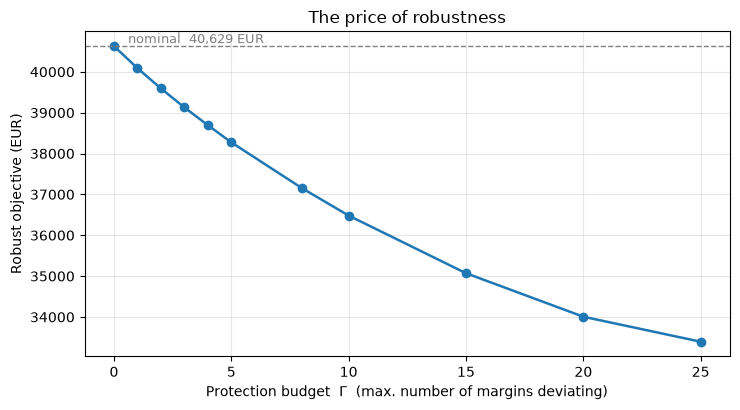

Protecting against a single bad surprise costs 540.00 EUR (1.33%).
Protecting against all of them costs 7,234.50 EUR (17.81%).
So the first unit of protection buys 7.5% of the total cost of full protection.


In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(robust_curve.gamma, robust_curve.objective, marker="o", lw=1.8)
ax.axhline(z0, ls="--", lw=1, color="grey")
ax.annotate(f"nominal  {z0:,.0f} EUR", xy=(0.6, z0), fontsize=9,
            va="bottom", color="grey")
ax.set_xlabel("Protection budget  $\\Gamma$  (max. number of margins deviating)")
ax.set_ylabel("Robust objective (EUR)")
ax.set_title("The price of robustness")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

first = robust_curve.iloc[1]
last = robust_curve.iloc[-1]
print(f"Protecting against a single bad surprise costs {first.loss:,.2f} EUR "
      f"({first.loss_pct:.2f}%).")
print(f"Protecting against all of them costs {last.loss:,.2f} EUR "
      f"({last.loss_pct:.2f}%).")
print(f"So the first unit of protection buys "
      f"{first.loss/last.loss:.1%} of the total cost of full protection.")

### 13.4 The result that was not expected: the assignment does not move

The objective falls as $\Gamma$ rises, as it must. But **no order enters, leaves, or changes
site at any $\Gamma$**. Robustness is, in this instance, purely a valuation effect: it changes
what we think the plan is worth, not what the plan is.

That is worth stating plainly rather than hiding, and it has a structural explanation. Two
conditions would have to fail for the assignment to move, and neither does.

In [28]:
print("CONDITION 1 - would refusing an accepted order ever help?\\n")
neg = [(i, margin[i]-delta[i]-TAU*d.loc[i, acc0[i]]) for i in acc0
       if margin[i]-delta[i]-TAU*d.loc[i, acc0[i]] < 0]
print(f"   Accepted orders whose FULLY-DEVIATED net margin is negative: {len(neg)}")
print("   Refusing an order forgoes its entire net margin to avoid only delta_i.")
print("   Since delta_i < m_i for every order, an accepted order stays profitable")
print("   even when fully deviated. Refusing is therefore never optimal.\\n")

print("CONDITION 2 - can two orders competing for a scarce resource swap ranks?\\n")
edm_orders = [i for i in I if h.loc[i, "EDM"] > 0]
print(f"   Orders requiring EDM (total network capacity {K['EDM'].sum():.0f} h):")
for i in edm_orders:
    st = "accepted" if i in acc0 else "REFUSED"
    print(f"     {i}  nominal {margin[i]:>6,}  worst-case {margin[i]-delta[i]:>8,.0f}  "
          f"EDM {h.loc[i,'EDM']:.0f}h   [{st}]")
print("\\n   A proportional deviation multiplies every margin by the same factor,")
print("   so the relative ranking is preserved and no swap can occur.")
print("\\n=> The invariance is structural, not a numerical accident.")

CONDITION 1 - would refusing an accepted order ever help?\n
   Accepted orders whose FULLY-DEVIATED net margin is negative: 0
   Refusing an order forgoes its entire net margin to avoid only delta_i.
   Since delta_i < m_i for every order, an accepted order stays profitable
   even when fully deviated. Refusing is therefore never optimal.\n
CONDITION 2 - can two orders competing for a scarce resource swap ranks?\n
   Orders requiring EDM (total network capacity 42 h):
     O05  nominal  3,600  worst-case    3,060  EDM 16h   [accepted]
     O15  nominal  3,300  worst-case    2,805  EDM 14h   [accepted]
     O22  nominal  2,750  worst-case    2,338  EDM 14h   [REFUSED]
\n   A proportional deviation multiplies every margin by the same factor,
   so the relative ranking is preserved and no swap can occur.
\n=> The invariance is structural, not a numerical accident.


### 13.5 What would it take to change the decision?

Since the assignment is invariant under the stated assumption, the useful question becomes:
how far would the assumption have to move before the decision itself changes?

Orders **O15** (nominal margin €3,300, accepted) and **O22** (€2,750, refused) compete for the
same scarce EDM capacity. Below, the uncertainty on O15 is raised while O22 is treated as a
reliable, low-variance job, the realistic case of a high-margin but risky order against a
safer, smaller one.

In [29]:
print(f"{'delta(O15)':>11} | {'O15 worst':>10} | {'O22 worst':>10} | "
      f"{'O22 accepted?':>14} | {'objective':>12}")
print("-" * 68)

flip = None
for pct in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    dm = {i: 0.15*margin[i] for i in I}
    dm["O15"] = pct * margin["O15"]
    dm["O22"] = 0.05 * margin["O22"]
    zt, acct = solve_robust(len(servable), delta_map=dm)
    took = "O22" in acct
    if took and flip is None:
        flip = pct
    print(f"{pct*margin['O15']:>11,.0f} | {margin['O15']-pct*margin['O15']:>10,.0f} | "
          f"{margin['O22']*0.95:>10,.0f} | {str(took):>14} | {zt:>12,.2f}")

print("-" * 68)
if flip:
    print(f"\\nThe decision flips at delta(O15) = {flip:.0%} of nominal margin.\\n")
    print("Note the gap with the naive pairwise reading. Comparing worst-case margins")
    print("alone, O22 overtakes O15 at around 33%. The model only switches at "
          f"{flip:.0%}.")
    print("The pairwise heuristic is wrong here because the two orders do not consume")
    print("the same resources - swapping them displaces other assignments as well.")
    print("This is precisely the kind of interaction an assignment model captures and")
    print("a rule of thumb does not.")

 delta(O15) |  O15 worst |  O22 worst |  O22 accepted? |    objective
--------------------------------------------------------------------


        495 |      2,805 |      2,612 |          False |    33,394.14


        660 |      2,640 |      2,612 |          False |    33,229.14


        825 |      2,475 |      2,612 |          False |    33,064.14


        990 |      2,310 |      2,612 |          False |    32,899.14


      1,155 |      2,145 |      2,612 |          False |    32,734.14


      1,320 |      1,980 |      2,612 |          False |    32,569.14


      1,485 |      1,815 |      2,612 |           True |    32,437.50


      1,650 |      1,650 |      2,612 |           True |    32,437.50
--------------------------------------------------------------------
\nThe decision flips at delta(O15) = 45% of nominal margin.\n
Note the gap with the naive pairwise reading. Comparing worst-case margins
alone, O22 overtakes O15 at around 33%. The model only switches at 45%.
The pairwise heuristic is wrong here because the two orders do not consume
the same resources - swapping them displaces other assignments as well.
This is precisely the kind of interaction an assignment model captures and
a rule of thumb does not.


### 13.6 What this section adds, and what it does not

**Adds.** Uncertainty is now inside the model rather than probed after the fact. The budget
parameter makes the conservatism explicit and adjustable, instead of being an implicit
all-or-nothing choice. And the counterpart is a genuine mixed-integer program, with continuous
dual variables alongside the binary assignment variables.

**Does not add.** The deviation magnitudes are assumed, not estimated: 15% is a modelling
choice, and every number in this section inherits that assumption. The model protects against
adversarial deviation within a budget, which is not the same as optimising expected value under
a probability distribution; if the distribution were known, stochastic programming would be the
better tool. And uncertainty here is confined to margins. Capacity is still treated as certain,
though a machine breakdown is at least as plausible as a margin miss. That would be the natural
next extension, with the budget applied to the right-hand side instead of the objective.

## 14. Summary

| | |
|---|---|
| **Problem class** | Generalised assignment problem; NP-hard as a class, under a second on this instance |
| **Variables** | Binary $x_{i,c}$, one per compatible (order, campus) pair |
| **Objective** | Maximise total net margin = gross margin − logistics cost |
| **Constraints** | Each order assigned at most once; machine-hour capacity per campus per process |
| **Solver** | CBC via PuLP |
| **Baseline** | Greedy nearest-campus rule, measured in Section 7.2 rather than assumed |
| **Duality** | Read on the linear relaxation, with the integrality gap measured and the transfer to the MILP tested empirically |

The two results worth carrying out of this notebook are not the objective value. They are:

1. **Refusal has two separable causes**, capability and capacity, and only the model
   separates them cleanly. They demand different managerial responses: investment or
   partnership in one case, pricing and arbitration in the other.

2. **Stranded capacity is invisible to utilisation metrics.** Idle hours that sit on the
   wrong campus, in insufficient quantity for any single indivisible order, are real capacity
   and unusable capacity at the same time. A percentage cannot show that; an assignment model
   can.